In [1]:
import glob
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
grid_file = glob.glob('data/grids_100_*.parquet')[0]   # pilot: first grid
gdf = gpd.read_parquet(grid_file)

# Columns the 02_* notebooks add. Only those present are plotted.
candidates = ['street_walk_length', 'num_street_intersections', 'pub_trans_count',
              'ndvi', 'ent_5', 'slope', 'population', 'dou']
cols = [c for c in candidates if c in gdf.columns]


Plotting: ['ent_5', 'slope', 'population', 'dou']


Plotting: ['ent_5', 'slope', 'population', 'dou']


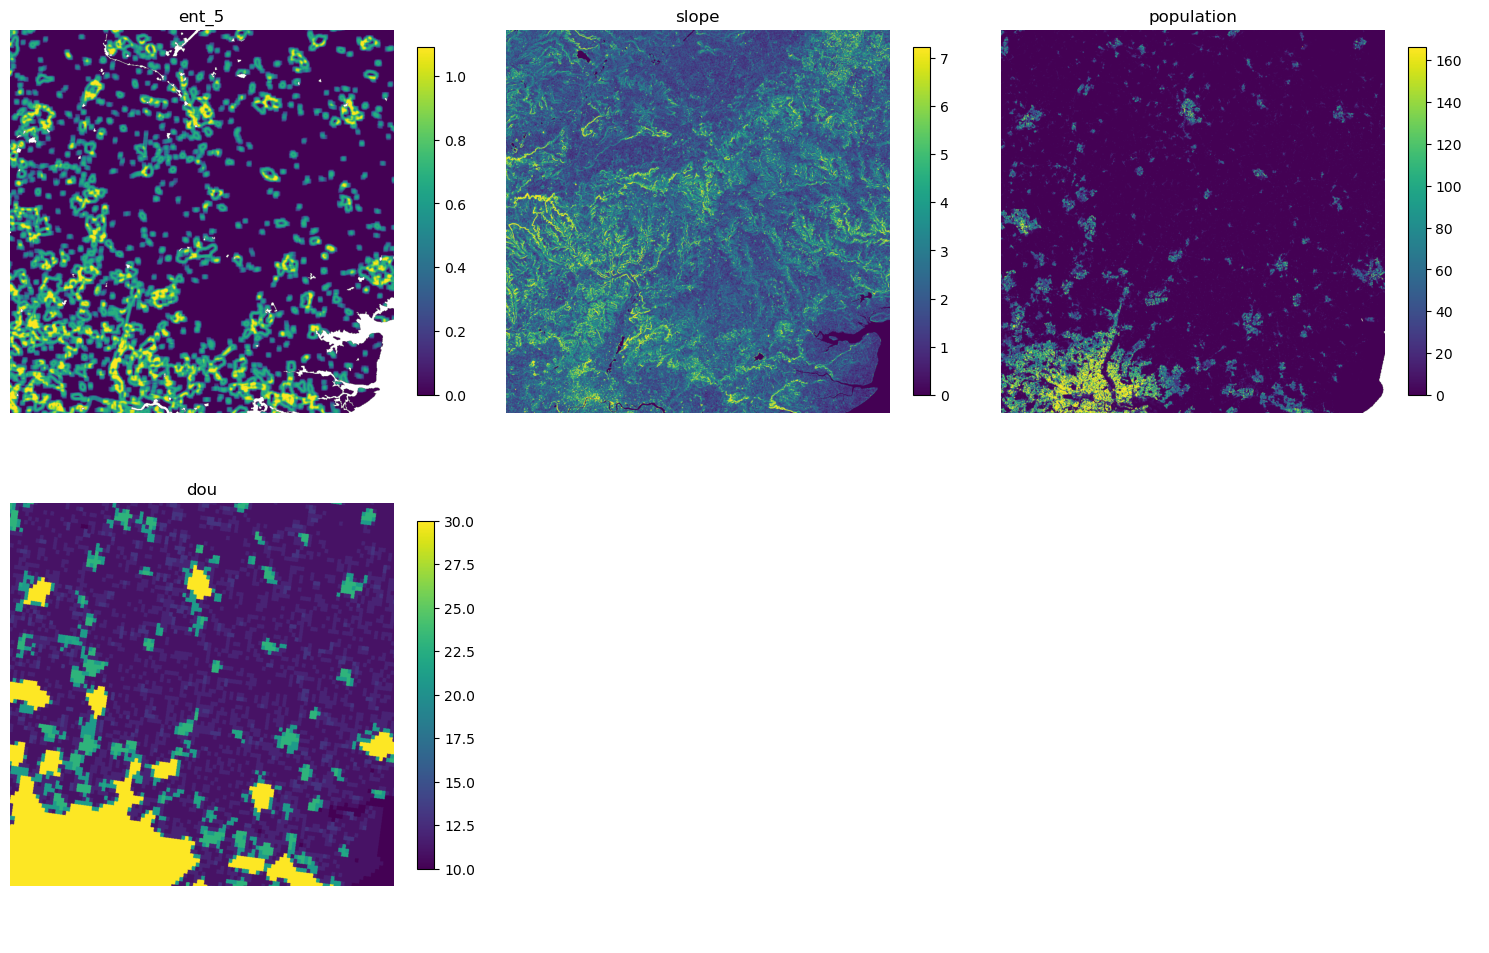

In [3]:
print("Plotting:", cols)

# Row/column position of each 100 m cell (grid is in metres, EPSG:3035)
b = gdf.geometry.bounds
col = ((b.minx - b.minx.min()) / 100).round().astype(int).to_numpy()
row = ((b.maxy.max() - b.maxy) / 100).round().astype(int).to_numpy()
shape = (row.max() + 1, col.max() + 1)

def to_raster(values):
    arr = np.full(shape, np.nan, dtype=np.float32)
    arr[row, col] = values
    return arr

n = len(cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, c in zip(axes, cols):
    vals = gdf[c].astype(float).to_numpy()
    if c in ('population', 'ndvi', 'ent_5'):
        vals = np.where(vals < 0, np.nan, vals)      # nodata / negatives, as 06 treats them
    arr = to_raster(vals)

    vmax = np.nanpercentile(arr, 99) if np.isfinite(arr).any() else None  # clip outliers
    im = ax.imshow(arr, cmap='viridis', vmin=0 if c != 'dou' else None, vmax=vmax)
    ax.set_title(c)
    ax.axis('off')
    fig.colorbar(im, ax=ax, shrink=0.7)

for ax in axes[n:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig('plots_02_maps.png', dpi=150)
plt.show()

Lon/Lat bounds: [np.float64(-0.6208336993004139), np.float64(1.017956963638567), np.float64(51.446941053655586), np.float64(52.456757169384545)]


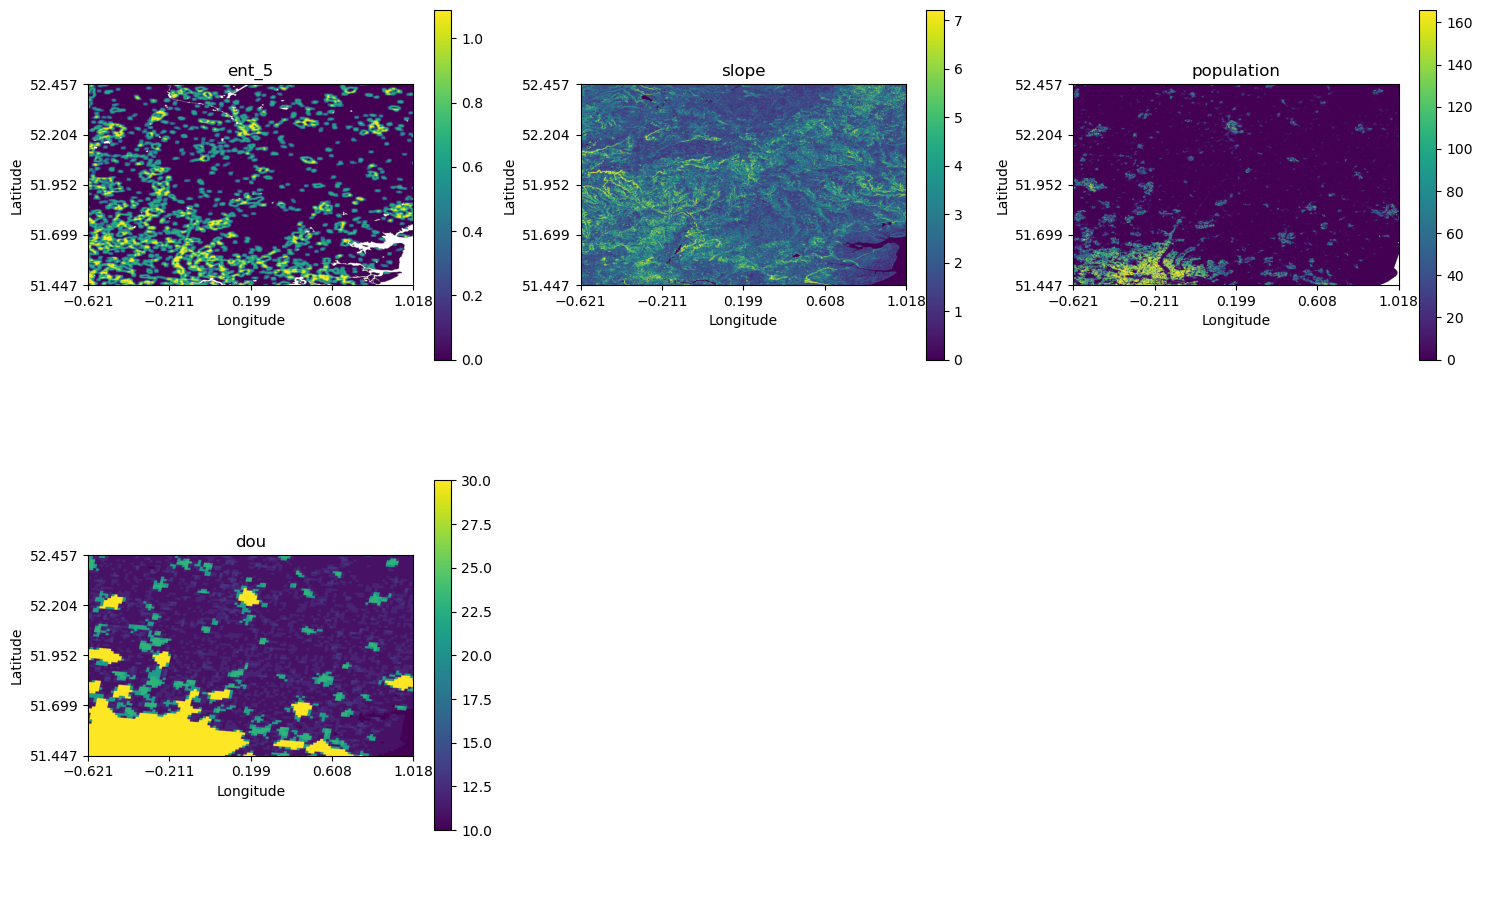

In [4]:
gdf_ll = gdf.to_crs("EPSG:4326")
minx, miny, maxx, maxy = gdf_ll.total_bounds
extent_ll = [minx, maxx, miny, maxy]  # [left, right, bottom, top]
print(f"Lon/Lat bounds: {extent_ll}")

n = len(cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, c in zip(axes, cols):
    vals = gdf[c].astype(float).to_numpy()
    if c in ('population', 'ndvi', 'ent_5'):
        vals = np.where(vals < 0, np.nan, vals)      # nodata / negatives, as 06 treats them
    arr = to_raster(vals)

    vmax = np.nanpercentile(arr, 99) if np.isfinite(arr).any() else None
    im = ax.imshow(
        arr,
        cmap='viridis',
        vmin=0 if c != 'dou' else None,
        vmax=vmax,
        extent=extent_ll,     # use lon/lat coordinates on axes
        origin='upper'
    )
    ax.set_title(c)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.ticklabel_format(style='plain', useOffset=False)

    # optional: tighten ticks to look map-like
    ax.set_xticks(np.linspace(minx, maxx, 5))
    ax.set_yticks(np.linspace(miny, maxy, 5))

    fig.colorbar(im, ax=ax, shrink=0.7)

for ax in axes[n:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig('plots_02_maps_with_axes.png', dpi=150)
plt.show()